In [1]:
import os, math, time, random, pickle, json
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torch.cuda.amp import autocast, GradScaler
import matplotlib.pyplot as plt

#
# سلول 2 — Device + AMP

In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
amp_enabled = device.type == "cuda"

print(f"Device: {device} | AMP: {amp_enabled}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"Memory: {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

Device: cuda | AMP: True
GPU: Tesla T4
Memory: 15.6 GB


#
# سلول 3 — Helper functions

In [3]:
def clones(module, N):
    return nn.ModuleList([module for _ in range(N)])

def subsequent_mask(size):
    attn_shape = (1, size, size)
    sub_mask = torch.triu(torch.ones(attn_shape), diagonal=1).bool()
    return ~sub_mask


# سلول 4 — MultiHeadAttention

In [21]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model, heads, dropout=0.1):
        super().__init__()
        assert d_model % heads == 0
        self.d_k = d_model // heads
        self.heads = heads
        self.linears = clones(nn.Linear(d_model, d_model), 4)
        self.dropout = nn.Dropout(dropout)

    def forward(self, query, key, value, mask=None):
        B = query.size(0)

        q, k, v = [
            lin(x).view(B, -1, self.heads, self.d_k).transpose(1, 2)
            for lin, x in zip(self.linears, (query, key, value))
        ]

        scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(self.d_k)

        if mask is not None:
            # expand mask to (B, 1, seq_q, seq_k) so it broadcasts over heads
            while mask.dim() < scores.dim():
                mask = mask.unsqueeze(1)
            scores = scores.masked_fill(~mask, torch.finfo(scores.dtype).min)

        attn = F.softmax(scores, dim=-1)
        attn = self.dropout(attn)

        out = torch.matmul(attn, v)
        out = out.transpose(1, 2).contiguous().view(B, -1, self.heads * self.d_k)
        return self.linears[3](out)


# سلول 5 — FeedForward

In [5]:
class FeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.w1 = nn.Linear(d_model, d_ff)
        self.w2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.w2(self.dropout(F.relu(self.w1(x))))


# سلول 6 — PositionalEncoding

In [6]:
class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=5000, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(dropout)

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len).unsqueeze(1).float()
        div_term = torch.exp(
            torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)
        pe = pe.unsqueeze(0)  # (1, max_len, d_model)
        self.register_buffer("pe", pe)

    def forward(self, x):
        x = x + self.pe[:, :x.size(1)]
        return self.dropout(x)


# سلول 7 — EncoderLayer (Pre-LN)

In [7]:
class EncoderLayer(nn.Module):
    def __init__(self, d_model, heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, heads, dropout)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)

    def forward(self, x, mask):
        x_norm = self.norm1(x)
        attn_out = self.self_attn(x_norm, x_norm, x_norm, mask)
        x = x + self.dropout1(attn_out)

        ff_out = self.feed_forward(self.norm2(x))
        x = x + self.dropout2(ff_out)
        return x


# سلول 8 — DecoderLayer (Pre-LN)

In [8]:
class DecoderLayer(nn.Module):
    def __init__(self, d_model, heads, d_ff, dropout=0.1):
        super().__init__()
        self.self_attn = MultiHeadAttention(d_model, heads, dropout)
        self.cross_attn = MultiHeadAttention(d_model, heads, dropout)
        self.feed_forward = FeedForward(d_model, d_ff, dropout)
        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.norm3 = nn.LayerNorm(d_model)
        self.dropout1 = nn.Dropout(dropout)
        self.dropout2 = nn.Dropout(dropout)
        self.dropout3 = nn.Dropout(dropout)

    def forward(self, x, memory, src_mask, tgt_mask):
        x_norm = self.norm1(x)
        self_attn_out = self.self_attn(x_norm, x_norm, x_norm, tgt_mask)
        x = x + self.dropout1(self_attn_out)

        x_norm = self.norm2(x)
        cross_attn_out = self.cross_attn(x_norm, memory, memory, src_mask)
        x = x + self.dropout2(cross_attn_out)

        ff_out = self.feed_forward(self.norm3(x))
        x = x + self.dropout3(ff_out)
        return x


# سلول 9 — Encoder + Decoder

In [9]:
class Encoder(nn.Module):
    def __init__(self, layer, N, d_model):
        super().__init__()
        self.layers = clones(layer, N)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, mask):
        for layer in self.layers:
            x = layer(x, mask)
        return self.norm(x)


class Decoder(nn.Module):
    def __init__(self, layer, N, d_model):
        super().__init__()
        self.layers = clones(layer, N)
        self.norm = nn.LayerNorm(d_model)

    def forward(self, x, memory, src_mask, tgt_mask):
        for layer in self.layers:
            x = layer(x, memory, src_mask, tgt_mask)
        return self.norm(x)


# سلول 10 — Generator + Transformer

In [10]:
class Generator(nn.Module):
    def __init__(self, d_model, vocab):
        super().__init__()
        self.proj = nn.Linear(d_model, vocab)

    def forward(self, x):
        return F.log_softmax(self.proj(x), dim=-1)


class Transformer(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d_model=128, N=3, heads=8,
                 d_ff=256, dropout=0.1, max_len=5000):
        super().__init__()
        enc_layer = EncoderLayer(d_model, heads, d_ff, dropout)
        dec_layer = DecoderLayer(d_model, heads, d_ff, dropout)
        self.encoder = Encoder(enc_layer, N, d_model)
        self.decoder = Decoder(dec_layer, N, d_model)
        self.src_embed = nn.Embedding(src_vocab, d_model)
        self.tgt_embed = nn.Embedding(tgt_vocab, d_model)
        self.pos_enc = PositionalEncoding(d_model, max_len, dropout)
        self.generator = Generator(d_model, tgt_vocab)
        self.d_model = d_model

    def encode(self, src, src_mask):
        x = self.pos_enc(self.src_embed(src) * math.sqrt(self.d_model))
        return self.encoder(x, src_mask)

    def decode(self, memory, src_mask, tgt, tgt_mask):
        x = self.pos_enc(self.tgt_embed(tgt) * math.sqrt(self.d_model))
        return self.decoder(x, memory, src_mask, tgt_mask)

    def forward(self, src, tgt, src_mask, tgt_mask):
        memory = self.encode(src, src_mask)
        dec_out = self.decode(memory, src_mask, tgt, tgt_mask)
        return self.generator(dec_out)

# سلول 11 — Label-smoothed loss


In [11]:
def label_smoothed_nll_loss(log_probs, target, smoothing=0.1, ignore_index=-100):
    N, V = log_probs.size()
    mask = (target != ignore_index).float()

    with torch.no_grad():
        true_dist = torch.zeros_like(log_probs)
        true_dist.fill_(smoothing / (V - 1))
        safe_target = target.clone()
        safe_target[safe_target == ignore_index] = 0
        true_dist.scatter_(1, safe_target.unsqueeze(1), 1.0 - smoothing)

    loss_per_token = -(true_dist * log_probs).sum(dim=1)
    return (loss_per_token * mask).sum() / mask.sum().clamp(min=1)

# سلول 12 — EarlyStopping


In [12]:
class EarlyStopping:
    def __init__(self, patience=4, min_delta=1e-4):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.should_stop = False

    def step(self, val_loss):
        if self.best_loss is None or val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.should_stop = True
        return self.should_stop

# سلول 13 — Mount Google Drive


In [13]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
    print("Not in Colab — using local paths")

PROJECT_ROOT = Path("/content/drive/MyDrive/persian_spell_corrector") if IN_COLAB \
               else Path("./persian_spell_corrector")
DATA_DIR = PROJECT_ROOT / "data"
CKPT_DIR = PROJECT_ROOT / "checkpoints"
LOG_DIR  = PROJECT_ROOT / "logs"
DEMO_DIR = PROJECT_ROOT / "demo"

for d in [DATA_DIR, CKPT_DIR, LOG_DIR, DEMO_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")

Mounted at /content/drive
Project root: /content/drive/MyDrive/persian_spell_corrector



# سلول 14 — PersianCharVocab

In [14]:
FA_CHARS = list(
    "آابپتثجچحخدذرزژسشصضطظعغفقکگلمنوهی"
    "ئءأإؤ"
    "٠١٢٣٤٥٦٧٨٩"
    "0123456789"
    "abcdefghijklmnopqrstuvwxyz"
    "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
    " .,;:!?؟،«»()-'\""
    "\u200c"                # نیم‌فاصله
    "ًٌٍَُِّْ"
    "ـ"
)

SPECIAL_TOKENS = ["<pad>", "<sos>", "<eos>", "<unk>"]
N_SPECIAL = len(SPECIAL_TOKENS)


class PersianCharVocab:
    def __init__(self, chars=None):
        chars = chars if chars is not None else FA_CHARS
        unique = []
        for c in chars:
            if c not in unique:
                unique.append(c)

        self.char_to_idx = {c: i + N_SPECIAL for i, c in enumerate(unique)}
        self.idx_to_char = {i + N_SPECIAL: c for i, c in enumerate(unique)}

        self.pad_idx = 0
        self.sos_idx = 1
        self.eos_idx = 2
        self.unk_idx = 3
        self.size = N_SPECIAL + len(unique)

    def encode(self, text, add_sos=False, add_eos=False):
        ids = [self.char_to_idx.get(c, self.unk_idx) for c in text]
        if add_sos:
            ids = [self.sos_idx] + ids
        if add_eos:
            ids = ids + [self.eos_idx]
        return ids

    def decode(self, ids, skip_special=True):
        out = []
        for i in ids:
            if skip_special and i < N_SPECIAL:
                continue
            out.append(self.idx_to_char.get(int(i), "?"))
        return "".join(out)


vocab_fa = PersianCharVocab()
print(f"Vocab size: {vocab_fa.size}")
print(f"Encode test: {vocab_fa.encode('سلام', add_sos=True, add_eos=True)}")
print(f"Decode test: {vocab_fa.decode(vocab_fa.encode('سلام دنیا'))}")

Vocab size: 140
Encode test: [1, 19, 31, 5, 32, 2]
Decode test: سلام دنیا


# سلول 15 — تولید دیتاست + ذخیره در Drive


In [15]:
random.seed(42)

SEED_SENTENCES = [
    "سلام حال شما چطور است",
    "امروز هوا خیلی خوب است",
    "من کتاب می‌خوانم",
    "او به مدرسه می‌رود",
    "ما در تهران زندگی می‌کنیم",
    "این غذا خیلی خوشمزه است",
    "کتاب روی میز است",
    "برنامه‌نویسی خیلی جذاب است",
    "دانشجو در کتابخانه مطالعه می‌کند",
    "هواپیما ساعت هشت پرواز می‌کند",
    "پدرم در شرکت کار می‌کند",
    "مادرم غذا می‌پزد",
    "بچه‌ها در حیاط بازی می‌کنند",
    "من فارسی یاد می‌گیرم",
    "کامپیوتر جدید خریدم",
    "امروز جلسه مهمی داریم",
    "این فیلم خیلی قشنگ بود",
    "شهر تهران بزرگ است",
    "درخت‌های باغ شکوفه داده‌اند",
    "موسیقی ایرانی زیباست",
    "چای داغ می‌نوشیم",
    "نتیجه امتحان فردا اعلام می‌شود",
    "من به موسیقی گوش می‌دهم",
    "هوای زمستان سرد است",
    "برف روی کوه‌ها نشسته است",
    "دوست من در دانشگاه درس می‌خواند",
    "این ساختمان بلند است",
    "ساعت ده شب به خانه رسیدم",
    "رنگ آسمان آبی است",
    "ماهی در دریا شنا می‌کند",
    "پرنده روی شاخه آواز می‌خواند",
    "غذا با برنج و خورش است",
    "او کتاب جدیدی نوشت",
    "قطار ساعت شش حرکت می‌کند",
    "درخت سیب در باغ است",
    "نقاشی روی دیوار آویزان است",
    "من هر روز ورزش می‌کنم",
    "همسایه ما مهندس است",
    "این ماشین خیلی سریع است",
    "بچه گربه در حیاط است",
]

CHAR_CONFUSIONS = {
    "ک": "ك", "ك": "ک",
    "ی": "ي", "ي": "ی",
    "ه": "ة", "ة": "ه",
    "ا": "أ", "أ": "ا",
    "و": "ؤ", "ؤ": "و",
    "\u200c": " ",
}

FA_LETTERS = list("ابپتثجچحخدذرزژسشصضطظعغفقکگلمنوهی")


def corrupt_word(word, g):
    if len(word) <= 1:
        return word
    op = g.choice(["drop", "insert", "substitute", "swap", "confuse", "multi"])
    chars = list(word)

    if op == "drop" and len(chars) > 2:
        chars.pop(g.randrange(len(chars)))
    elif op == "insert":
        chars.insert(g.randrange(len(chars) + 1), g.choice(FA_LETTERS))
    elif op == "substitute":
        chars[g.randrange(len(chars))] = g.choice(FA_LETTERS)
    elif op == "swap" and len(chars) > 2:
        i = g.randrange(len(chars) - 1)
        chars[i], chars[i + 1] = chars[i + 1], chars[i]
    elif op == "confuse":
        for i in range(len(chars)):
            if chars[i] in CHAR_CONFUSIONS and g.random() < 0.5:
                chars[i] = CHAR_CONFUSIONS[chars[i]]
                break
    elif op == "multi":
        for _ in range(g.randint(1, 3)):
            if len(chars) > 2 and g.random() < 0.5:
                chars.pop(g.randrange(len(chars)))
            else:
                chars[g.randrange(len(chars))] = g.choice(FA_LETTERS)

    return "".join(chars)


def corrupt_sentence(sentence, g, p_word=0.35):
    words = sentence.split(" ")
    return " ".join(
        corrupt_word(w, g) if (g.random() < p_word and len(w) > 0) else w
        for w in words
    )


def build_dataset(n_samples, g):
    pairs = []
    for _ in range(n_samples):
        base = g.choice(SEED_SENTENCES)
        if g.random() < 0.3:
            base = (base + " " + g.choice(SEED_SENTENCES)).strip()
        bad = corrupt_sentence(base, g, p_word=g.uniform(0.2, 0.5))
        if bad != base:
            pairs.append((bad, base))
    return pairs


TRAIN_PATH = DATA_DIR / "train_pairs.pkl"
VAL_PATH   = DATA_DIR / "val_pairs.pkl"

g = random.Random(42)

if TRAIN_PATH.exists() and VAL_PATH.exists():
    print("Dataset exists in Drive — loading...")
    with open(TRAIN_PATH, "rb") as f:
        train_pairs = pickle.load(f)
    with open(VAL_PATH, "rb") as f:
        val_pairs = pickle.load(f)
    print(f"Train: {len(train_pairs):,} | Val: {len(val_pairs):,}")
else:
    print("Generating dataset (30-60 sec)...")
    train_pairs = build_dataset(80_000, g)
    val_pairs   = build_dataset(4_000, g)
    with open(TRAIN_PATH, "wb") as f:
        pickle.dump(train_pairs, f)
    with open(VAL_PATH, "wb") as f:
        pickle.dump(val_pairs, f)
    print(f"Saved to Drive")
    print(f"Train: {len(train_pairs):,} | Val: {len(val_pairs):,}")
    print(f"Size: {TRAIN_PATH.stat().st_size/1e6:.2f} MB")

for i in range(3):
    print(f"\n[{i+1}] bad : {train_pairs[i][0]}")
    print(f"    good: {train_pairs[i][1]}")

Generating dataset (30-60 sec)...
Saved to Drive
Train: 66,547 | Val: 3,307
Size: 6.12 MB

[1] bad : برنامه‌نویی خیلی جذاب است هر تةران باغس چست
    good: برنامه‌نویسی خیلی جذاب است شهر تهران بزرگ است

[2] bad : برف روی کوه‌ها نشسته أست من به موسیقثی گوجش می‌دهم
    good: برف روی کوه‌ها نشسته است من به موسیقی گوش می‌دهم

[3] bad : کتاب روژ ذذ است
    good: کتاب روی میز است


# سلول 16 — SpellDataset


In [16]:
class SpellDataset(torch.utils.data.Dataset):
    def __init__(self, pairs, vocab, max_len=64):
        self.vocab = vocab
        self.max_len = max_len
        self.samples = []
        for bad, good in pairs:
            src_ids = vocab.encode(bad[:max_len])
            tgt_ids = vocab.encode(good[:max_len], add_sos=True, add_eos=True)
            self.samples.append((src_ids, tgt_ids))

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        return self.samples[idx]


MAX_LEN = 64
train_ds = SpellDataset(train_pairs, vocab_fa, MAX_LEN)
val_ds   = SpellDataset(val_pairs,   vocab_fa, MAX_LEN)

print(f"Train: {len(train_ds):,} | Val: {len(val_ds):,}")
src_ids, tgt_ids = train_ds[0]
print(f"src decoded: {vocab_fa.decode(src_ids)}")
print(f"tgt decoded: {vocab_fa.decode(tgt_ids)}")

Train: 66,547 | Val: 3,307
src decoded: برنامه‌نویی خیلی جذاب است هر تران باغس چست
tgt decoded: برنامه‌نویسی خیلی جذاب است شهر تهران بزرگ است


# سلول 17 — Collate function + DataLoader


In [17]:
def make_collate_fn(vocab, max_len):
    causal_full = subsequent_mask(max_len + 2)

    def collate_fn(batch):
        srcs, tgts = zip(*batch)
        max_src = max(len(s) for s in srcs)
        max_tgt = max(len(t) for t in tgts)
        B = len(batch)

        src_padded   = torch.full((B, max_src), vocab.pad_idx, dtype=torch.long)
        tgt_padded   = torch.full((B, max_tgt), vocab.pad_idx, dtype=torch.long)
        src_pad_mask = torch.zeros(B, max_src, dtype=torch.bool)
        tgt_pad_mask = torch.zeros(B, max_tgt, dtype=torch.bool)

        for i, (s, t) in enumerate(zip(srcs, tgts)):
            src_padded[i, :len(s)]   = torch.tensor(s, dtype=torch.long)
            tgt_padded[i, :len(t)]   = torch.tensor(t, dtype=torch.long)
            src_pad_mask[i, :len(s)] = True
            tgt_pad_mask[i, :len(t)] = True

        causal   = causal_full[:, :max_tgt, :max_tgt]
        tgt_mask = causal & tgt_pad_mask.unsqueeze(1)
        diag     = torch.eye(max_tgt, dtype=torch.bool).unsqueeze(0)
        tgt_mask = tgt_mask | diag

        src_mask = src_pad_mask.unsqueeze(1)

        return {
            "src": src_padded,
            "tgt": tgt_padded,
            "src_mask": src_mask,
            "tgt_mask": tgt_mask,
        }

    return collate_fn


collate_fn = make_collate_fn(vocab_fa, MAX_LEN)
BATCH_SIZE = 64

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,
    collate_fn=collate_fn, drop_last=True, num_workers=0, pin_memory=True,
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False,
    collate_fn=collate_fn, num_workers=0, pin_memory=True,
)

b = next(iter(train_loader))
print(f"src: {tuple(b['src'].shape)}")
print(f"tgt: {tuple(b['tgt'].shape)}")
print(f"src_mask: {tuple(b['src_mask'].shape)}")
print(f"tgt_mask: {tuple(b['tgt_mask'].shape)}")

src: (64, 55)
tgt: (64, 58)
src_mask: (64, 1, 55)
tgt_mask: (64, 58, 58)


# سلول 18 — Model config + init


In [22]:
class CFG:
    V         = vocab_fa.size
    pad_idx   = vocab_fa.pad_idx
    d_model   = 128
    N         = 3
    heads     = 8
    d_ff      = 256
    dropout   = 0.1

    batch_size       = BATCH_SIZE
    epochs           = 25
    patience         = 4
    grad_accum_steps = 2
    lr               = 1e-3
    warmup_steps     = 1000
    grad_clip        = 1.0
    label_smoothing  = 0.05

    max_len    = MAX_LEN
    ckpt_path  = str(CKPT_DIR / "best_spell_corrector.pt")
    log_dir    = str(LOG_DIR / "spell_corrector")


cfg = CFG()

model = Transformer(
    src_vocab=cfg.V,
    tgt_vocab=cfg.V,
    d_model=cfg.d_model,
    N=cfg.N,
    heads=cfg.heads,
    d_ff=cfg.d_ff,
    dropout=cfg.dropout,
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Model params: {n_params:,}")

Model params: 237,068


# سلول 19 — Optimizer, Scheduler, Scaler


In [23]:
optimizer = torch.optim.AdamW(
    model.parameters(), lr=cfg.lr, betas=(0.9, 0.98),
    eps=1e-9, weight_decay=0.01,
)

def lr_lambda(step):
    step = max(step, 1)
    return min(step ** -0.5, step * (cfg.warmup_steps ** -1.5))

scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)
scaler = GradScaler(enabled=amp_enabled)
early_stopping = EarlyStopping(patience=cfg.patience, min_delta=1e-4)

try:
    from torch.utils.tensorboard import SummaryWriter
    writer = SummaryWriter(log_dir=cfg.log_dir)
    print(f"TensorBoard: {cfg.log_dir}")
except ImportError:
    writer = None
    print("TensorBoard not available")

TensorBoard: /content/drive/MyDrive/persian_spell_corrector/logs/spell_corrector


/tmp/ipykernel_3708/2003419448.py:11: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = GradScaler(enabled=amp_enabled)


#
# سلول 20 — Training loop

/tmp/ipykernel_3708/4038255671.py:24: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=amp_enabled):
/tmp/ipykernel_3708/4038255671.py:68: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with autocast(enabled=amp_enabled):


Epoch 01/25 | train=4.9881 | val=4.5824 | lr=1.64e-05 | 35.9s [saved]
Epoch 02/25 | train=3.7652 | val=3.0512 | lr=3.10e-05 | 34.1s [saved]
Epoch 03/25 | train=2.8574 | val=2.6734 | lr=2.53e-05 | 34.9s [saved]
Epoch 04/25 | train=2.6188 | val=2.5274 | lr=2.19e-05 | 34.4s [saved]
Epoch 05/25 | train=2.5117 | val=2.4364 | lr=1.96e-05 | 34.6s [saved]
Epoch 06/25 | train=2.4384 | val=2.3621 | lr=1.79e-05 | 35.8s [saved]
Epoch 07/25 | train=2.3787 | val=2.2970 | lr=1.66e-05 | 34.0s [saved]
Epoch 08/25 | train=2.3286 | val=2.2424 | lr=1.55e-05 | 35.1s [saved]
Epoch 09/25 | train=2.2870 | val=2.1965 | lr=1.46e-05 | 34.4s [saved]
Epoch 10/25 | train=2.2514 | val=2.1560 | lr=1.39e-05 | 35.6s [saved]
Epoch 11/25 | train=2.2196 | val=2.1187 | lr=1.32e-05 | 35.3s [saved]
Epoch 12/25 | train=2.1898 | val=2.0824 | lr=1.27e-05 | 34.2s [saved]
Epoch 13/25 | train=2.1616 | val=2.0482 | lr=1.22e-05 | 35.0s [saved]
Epoch 14/25 | train=2.1346 | val=2.0157 | lr=1.17e-05 | 34.1s [saved]
Epoch 15/25 | train=

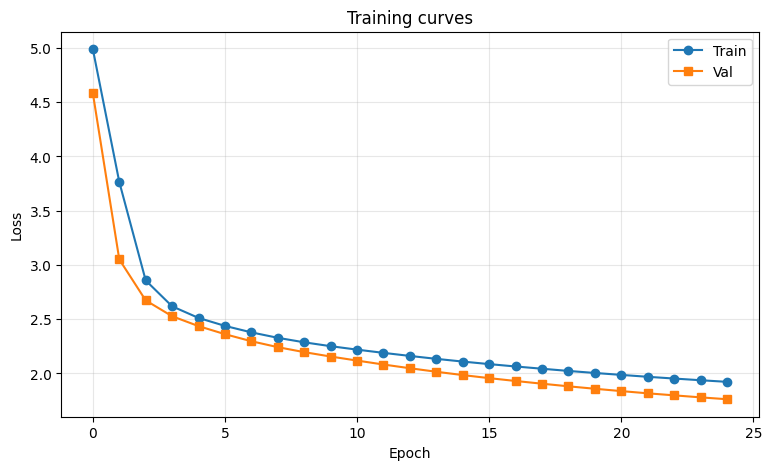

Best val loss: 1.7626
Checkpoint: /content/drive/MyDrive/persian_spell_corrector/checkpoints/best_spell_corrector.pt


In [24]:
train_losses = []
val_losses = []
best_val_loss = float("inf")
global_step = 0

for epoch in range(cfg.epochs):
    model.train()
    epoch_train_loss = 0.0
    n_batches = 0
    t0 = time.time()

    optimizer.zero_grad(set_to_none=True)

    for batch in train_loader:
        src      = batch["src"].to(device, non_blocking=True)
        tgt      = batch["tgt"].to(device, non_blocking=True)
        src_mask = batch["src_mask"].to(device, non_blocking=True)
        tgt_mask = batch["tgt_mask"].to(device, non_blocking=True)

        tgt_input   = tgt[:, :-1]
        tgt_output  = tgt[:, 1:]
        tgt_mask_in = tgt_mask[:, :-1, :-1]

        with autocast(enabled=amp_enabled):
            log_probs = model(src, tgt_input, src_mask, tgt_mask_in)
            loss = label_smoothed_nll_loss(
                log_probs.reshape(-1, cfg.V),
                tgt_output.reshape(-1),
                smoothing=cfg.label_smoothing,
                ignore_index=cfg.pad_idx,
            )

        scaler.scale(loss / cfg.grad_accum_steps).backward()

        epoch_train_loss += loss.item()
        n_batches += 1

        if n_batches % cfg.grad_accum_steps == 0:
            if amp_enabled:
                scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)

            if writer is not None:
                writer.add_scalar("train/loss_step", loss.item(), global_step)
                writer.add_scalar("train/lr", scheduler.get_last_lr()[0], global_step)
            global_step += 1

    avg_train_loss = epoch_train_loss / max(n_batches, 1)

    model.eval()
    epoch_val_loss = 0.0
    n_val = 0
    with torch.no_grad():
        for batch in val_loader:
            src      = batch["src"].to(device, non_blocking=True)
            tgt      = batch["tgt"].to(device, non_blocking=True)
            src_mask = batch["src_mask"].to(device, non_blocking=True)
            tgt_mask = batch["tgt_mask"].to(device, non_blocking=True)

            tgt_input   = tgt[:, :-1]
            tgt_output  = tgt[:, 1:]
            tgt_mask_in = tgt_mask[:, :-1, :-1]

            with autocast(enabled=amp_enabled):
                log_probs = model(src, tgt_input, src_mask, tgt_mask_in)
                v_loss = label_smoothed_nll_loss(
                    log_probs.reshape(-1, cfg.V),
                    tgt_output.reshape(-1),
                    smoothing=cfg.label_smoothing,
                    ignore_index=cfg.pad_idx,
                )
            epoch_val_loss += v_loss.item()
            n_val += 1

    avg_val_loss = epoch_val_loss / max(n_val, 1)
    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    if writer is not None:
        writer.add_scalar("epoch/train_loss", avg_train_loss, epoch)
        writer.add_scalar("epoch/val_loss", avg_val_loss, epoch)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        torch.save({
            "model_state_dict": model.state_dict(),
            "cfg": cfg.__dict__,
            "vocab_size": vocab_fa.size,
            "best_val_loss": best_val_loss,
            "epoch": epoch,
        }, cfg.ckpt_path)
        saved_msg = " [saved]"
    else:
        saved_msg = ""

    dt = time.time() - t0
    print(f"Epoch {epoch+1:02d}/{cfg.epochs} | "
          f"train={avg_train_loss:.4f} | val={avg_val_loss:.4f} | "
          f"lr={scheduler.get_last_lr()[0]:.2e} | {dt:.1f}s{saved_msg}")

    if early_stopping.step(avg_val_loss):
        print(f"Early stopping at epoch {epoch+1}")
        break

if writer is not None:
    writer.close()

plt.figure(figsize=(9, 5))
plt.plot(train_losses, label="Train", marker="o")
plt.plot(val_losses,   label="Val",   marker="s")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Training curves"); plt.legend(); plt.grid(True, alpha=0.3)
plt.show()

print(f"Best val loss: {best_val_loss:.4f}")
print(f"Checkpoint: {cfg.ckpt_path}")